In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import xml.etree.ElementTree as ET
from matplotlib.ticker import FuncFormatter
from pyspark.sql import SparkSession
from pyspark.sql.functions import count
from pyspark.sql.functions import col, count, median, sum
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler, OneHotEncoder, StringIndexer
from pyspark.ml import Pipeline
from pyspark.sql.functions import when, col
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, Imputer
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
# import pyspark.pandas as ps
import warnings
from sklearn.impute import KNNImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
warnings.filterwarnings("ignore")
import os
os.environ["PYARROW_IGNORE_TIMEZONE"] = "1"

In [8]:
# Create a SparkSession
spark_context= SparkSession.builder \
    .appName("RedliningAnalysis") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

In [9]:
file_path = "hmda_random_sample_2020_2023.csv"
truist_census = spark_context.read.csv(file_path, inferSchema=True, header=True)

In [10]:
truist_census_df = truist_census.toPandas()

### EDA, let's see how many nulls

In [11]:
truist_census_df.shape

(1000000, 99)

In [12]:
for col in truist_census_df.columns:
    print(col + " " + str(truist_census_df[col].dtype))

activity_year int32
lei object
derived_msa-md int32
state_code object
county_code float64
census_tract float64
conforming_loan_limit object
derived_loan_product_type object
derived_dwelling_category object
derived_ethnicity object
derived_race object
derived_sex object
action_taken int32
purchaser_type int32
preapproval int32
loan_type int32
loan_purpose int32
lien_status int32
reverse_mortgage int32
open-end_line_of_credit int32
business_or_commercial_purpose int32
loan_amount float64
loan_to_value_ratio object
interest_rate object
rate_spread object
hoepa_status int32
total_loan_costs object
total_points_and_fees object
origination_charges object
discount_points object
lender_credits object
loan_term object
prepayment_penalty_term object
intro_rate_period object
negative_amortization int32
interest_only_payment int32
balloon_payment int32
other_nonamortizing_features int32
property_value object
construction_method int32
occupancy_type int32
manufactured_home_secured_property_type int

In [13]:
# Check the null values
null_counts = truist_census_df.isnull().sum()
null_counts.sort_values(ascending=False).head(50)

co-applicant_ethnicity-5             999991
co-applicant_ethnicity-4             999989
applicant_ethnicity-5                999978
applicant_ethnicity-4                999967
co-applicant_ethnicity-3             999717
co-applicant_race-5                  999650
denial_reason-4                      999538
co-applicant_race-4                  999345
applicant_race-5                     999323
applicant_ethnicity-3                999242
applicant_race-4                     998485
co-applicant_race-3                  997695
aus-5                                996616
aus-4                                995949
denial_reason-3                      995889
applicant_race-3                     994367
aus-3                                987182
co-applicant_ethnicity-2             986202
co-applicant_race-2                  981197
denial_reason-2                      973626
multifamily_affordable_units         968693
total_points_and_fees                964391
applicant_ethnicity-2           

In [14]:
# ============================================================
# 🧹 Drop columns with >50% missing values
# ============================================================

threshold = 0.5  # 50% missing allowed
missing_fraction = truist_census_df.isnull().mean()  # fraction of missing per column

cols_to_drop = missing_fraction[missing_fraction > threshold].index
print(f"🧾 Columns to drop ({len(cols_to_drop)}):")
print(list(cols_to_drop))

# Drop them
truist_census_df.drop(columns=cols_to_drop, inplace=True)

print(f"\n✅ New dataset shape after dropping columns: {truist_census_df.shape}")


🧾 Columns to drop (30):
['total_points_and_fees', 'discount_points', 'lender_credits', 'prepayment_penalty_term', 'intro_rate_period', 'multifamily_affordable_units', 'applicant_ethnicity-2', 'applicant_ethnicity-3', 'applicant_ethnicity-4', 'applicant_ethnicity-5', 'co-applicant_ethnicity-2', 'co-applicant_ethnicity-3', 'co-applicant_ethnicity-4', 'co-applicant_ethnicity-5', 'applicant_race-2', 'applicant_race-3', 'applicant_race-4', 'applicant_race-5', 'co-applicant_race-2', 'co-applicant_race-3', 'co-applicant_race-4', 'co-applicant_race-5', 'co-applicant_age_above_62', 'aus-2', 'aus-3', 'aus-4', 'aus-5', 'denial_reason-2', 'denial_reason-3', 'denial_reason-4']

✅ New dataset shape after dropping columns: (1000000, 69)


In [15]:
# Check the null values
null_counts = truist_census_df.isnull().sum()
null_counts.sort_values(ascending=False).head(20)

rate_spread                     444648
total_loan_costs                437272
origination_charges             430558
loan_to_value_ratio             327898
debt_to_income_ratio            327706
interest_rate                   300820
property_value                  202441
income                          136747
applicant_age_above_62          101121
loan_term                        11321
census_tract                     10586
county_code                       7759
conforming_loan_limit             3925
applicant_ethnicity-1              410
co-applicant_ethnicity-1           144
applicant_race-1                   122
co-applicant_race-1                 50
applicant_ethnicity_observed         0
applicant_race_observed              0
co-applicant_race_observed           0
dtype: int64

In [16]:
print(len(truist_census_df.columns))
truist_census_df.columns

69


Index(['activity_year', 'lei', 'derived_msa-md', 'state_code', 'county_code',
       'census_tract', 'conforming_loan_limit', 'derived_loan_product_type',
       'derived_dwelling_category', 'derived_ethnicity', 'derived_race',
       'derived_sex', 'action_taken', 'purchaser_type', 'preapproval',
       'loan_type', 'loan_purpose', 'lien_status', 'reverse_mortgage',
       'open-end_line_of_credit', 'business_or_commercial_purpose',
       'loan_amount', 'loan_to_value_ratio', 'interest_rate', 'rate_spread',
       'hoepa_status', 'total_loan_costs', 'origination_charges', 'loan_term',
       'negative_amortization', 'interest_only_payment', 'balloon_payment',
       'other_nonamortizing_features', 'property_value', 'construction_method',
       'occupancy_type', 'manufactured_home_secured_property_type',
       'manufactured_home_land_property_interest', 'total_units', 'income',
       'debt_to_income_ratio', 'applicant_credit_score_type',
       'co-applicant_credit_score_type', 'ap

In [17]:
# Define the full list of desired columns
selected_features = [
    'loan_amount',
    'loan_to_value_ratio',
    'loan_type',
    'loan_purpose',
    'debt_to_income_ratio',
    'income',
    'loan_term',
    'interest_rate',
    'property_value',
    'applicant_credit_score_type',
    'derived_loan_product_type',
    'occupancy_type',
    'state_code',
    'county_code',
    'tract_to_msa_income_percentage',
    'tract_owner_occupied_units',
    'submission_of_application',
    'preapproval',
    'business_or_commercial_purpose',
    'activity_year',
    'rate_spread',
    'tract_minority_population_percent',
    'derived_race',
    'derived_ethnicity',
    'derived_sex',
    'applicant_age',
    'lei',
    'census_tract',
    'action_taken'
]

# Keep only columns that actually exist in your dataframe
available_features = [col for col in selected_features if col in truist_census_df.columns]

# Create the new dataframe with selected columns
selected_df = truist_census_df[available_features].copy()

# Print results
print(f"✅ Created dataset with {len(available_features)} features.")
print("Included columns:", available_features)

✅ Created dataset with 29 features.
Included columns: ['loan_amount', 'loan_to_value_ratio', 'loan_type', 'loan_purpose', 'debt_to_income_ratio', 'income', 'loan_term', 'interest_rate', 'property_value', 'applicant_credit_score_type', 'derived_loan_product_type', 'occupancy_type', 'state_code', 'county_code', 'tract_to_msa_income_percentage', 'tract_owner_occupied_units', 'submission_of_application', 'preapproval', 'business_or_commercial_purpose', 'activity_year', 'rate_spread', 'tract_minority_population_percent', 'derived_race', 'derived_ethnicity', 'derived_sex', 'applicant_age', 'lei', 'census_tract', 'action_taken']


In [18]:
# Check the null values
null_counts = selected_df.isnull().sum()
null_counts.sort_values(ascending=False).head(20)

rate_spread                          444648
loan_to_value_ratio                  327898
debt_to_income_ratio                 327706
interest_rate                        300820
property_value                       202441
income                               136747
loan_term                             11321
census_tract                          10586
county_code                            7759
loan_amount                               0
derived_race                              0
tract_minority_population_percent         0
applicant_age                             0
derived_ethnicity                         0
derived_sex                               0
business_or_commercial_purpose            0
lei                                       0
activity_year                             0
tract_to_msa_income_percentage            0
preapproval                               0
dtype: int64

In [19]:
# cols_to_check = ['loan_amount', 'property_value', 'rate_spread', 'interest_rate', 'debt_to_income_ratio', 'income']
cols_to_check = ['rate_spread', 'loan_to_value_ratio', 'debt_to_income_ratio', 'interest_rate', 'property_value', 'income', 'loan_term', 'census_tract', 'county_code']

display(selected_df[cols_to_check].head(10))

,rate_spread,loan_to_value_ratio,debt_to_income_ratio,interest_rate,property_value,income,loan_term,census_tract,county_code
0,None,96.103,>60%,None,165000,41.0,360,4.021001e+09,4021.0
1,None,None,None,3.5,505000.0,NaN,360.0,4.013061e+09,4013.0
2,0.282,77.61,30%-<36%,3.625,335000.0,106.0,360.0,4.013082e+09,4013.0
3,None,None,None,3.875,225000.0,NaN,360.0,4.013109e+09,4013.0
4,0.541,80.0,20%-<30%,2.875,155000,101.0,180,4.003000e+09,4003.0
5,0.363,72.34,49,2.75,235000,54.0,360,4.013093e+09,4013.0
6,None,None,None,None,None,NaN,360.0,4.013116e+09,4013.0
7,0.215,43.538,<20%,2.999,265000.0,69.0,360,4.013061e+09,4013.0
8,0.112,52.857,<20%,3.75,355000,89.0,360,4.025001e+09,4025.0
9,None,None,None,3.375,245000,74.0,360,4.013051e+09,4013.0


In [20]:
# Define the combinations you found
target_combinations = [
    (3, 5),
    (4, 5),
    (2, 5)
]

# Filter the dataframe for those combinations
subset = truist_census_df[
    truist_census_df[['loan_type', 'loan_purpose']]
    .apply(tuple, axis=1)
    .isin(target_combinations)
]

# Count total rows
total_rows = subset.shape[0]

print(f"Total rows with loan_type–loan_purpose combinations where DTI is ≥99% missing: {total_rows}")

# (Optional) show breakdown per combination
combo_counts = (
    subset.groupby(['loan_type', 'loan_purpose'])
    .size()
    .reset_index(name='row_count')
)
print("\nBreakdown by combination:")
print(combo_counts)


Total rows with loan_type–loan_purpose combinations where DTI is ≥99% missing: 6258

Breakdown by combination:
   loan_type  loan_purpose  row_count
0          2             5       4803
1          3             5        968
2          4             5        487


In [21]:
# Display data types of all columns in selected_df
for col in selected_df.columns:
    print(f"{col}: {selected_df[col].dtype}")


loan_amount: float64
loan_to_value_ratio: object
loan_type: int32
loan_purpose: int32
debt_to_income_ratio: object
income: float64
loan_term: object
interest_rate: object
property_value: object
applicant_credit_score_type: int32
derived_loan_product_type: object
occupancy_type: int32
state_code: object
county_code: float64
tract_to_msa_income_percentage: float64
tract_owner_occupied_units: int32
submission_of_application: int32
preapproval: int32
business_or_commercial_purpose: int32
activity_year: int32
rate_spread: object
tract_minority_population_percent: float64
derived_race: object
derived_ethnicity: object
derived_sex: object
applicant_age: object
lei: object
census_tract: float64
action_taken: int32


In [22]:
# List of columns to inspect
cols_to_check = [
    'loan_to_value_ratio',
    'debt_to_income_ratio',
    'loan_term',
    'interest_rate',
    'property_value',
    'derived_loan_product_type',
    'state_code',
    'rate_spread',
    'derived_race',
    'derived_ethnicity',
    'derived_sex',
    'applicant_age',
    'lei'
]

# Loop through columns and print top 5 percentage frequencies
for col in cols_to_check:
    if col in selected_df.columns:
        print(f"\n🔹 {col} — Top 5 value percentages:")
        print(
            (selected_df[col].value_counts(normalize=True, dropna=False) * 100)
            .round(2)
            .head(10)
        )
    else:
        print(f"\n⚠️ Column '{col}' not found in selected_df.")



🔹 loan_to_value_ratio — Top 5 value percentages:
loan_to_value_ratio
None      32.79
80.0       6.47
95.0       3.19
Exempt     2.91
96.5       2.69
100.0      2.34
90.0       2.02
75.0       1.80
97.0       1.05
70.0       0.85
Name: proportion, dtype: float64

🔹 debt_to_income_ratio — Top 5 value percentages:
debt_to_income_ratio
None        32.77
20%-<30%    12.50
30%-<36%    10.49
<20%         5.71
50%-60%      4.61
>60%         3.35
Exempt       2.89
44           2.40
42           2.37
41           2.18
Name: proportion, dtype: float64

🔹 loan_term — Top 5 value percentages:
loan_term
360       61.19
180        8.51
360.0      7.54
240        4.46
300        3.19
Exempt     2.90
120        2.73
None       1.13
180.0      1.01
60         0.96
Name: proportion, dtype: float64

🔹 interest_rate — Top 5 value percentages:
interest_rate
None      30.08
2.875      4.17
2.75       4.16
3.25       3.61
Exempt     2.90
3.125      2.66
3.0        2.52
3.375      2.38
3.5        2.16
2.625  

In [23]:

# --- 1️⃣ loan_to_value_ratio ---
def clean_loan_to_value(x):
    if pd.isna(x) or x in ["None", "", "Exempt"]:
        return np.nan
    try:
        return float(x)
    except:
        return np.nan

selected_df['loan_to_value_ratio'] = selected_df['loan_to_value_ratio'].apply(clean_loan_to_value)


# --- 2️⃣ debt_to_income_ratio ---
def parse_dti(x):
    if pd.isna(x) or x in ["None", "", "Exempt"]:
        return np.nan
    s = str(x).strip()
    if s.startswith("<20"):
        return 10.0
    elif s.startswith(">60"):
        return 70.0
    elif "%-" in s:  # range like 20%-<30%
        try:
            low = float(s.split("%")[0])
            high = float(s.split("<")[-1].replace("%", ""))
            return (low + high) / 2
        except:
            return np.nan
    else:
        try:
            return float(s)
        except:
            return np.nan

selected_df['debt_to_income_ratio'] = selected_df['debt_to_income_ratio'].apply(parse_dti)


# --- 3️⃣ loan_term ---
def clean_loan_term(x):
    if pd.isna(x) or x in ["None", "", "Exempt"]:
        return np.nan
    try:
        return float(x)
    except:
        return np.nan

selected_df['loan_term'] = selected_df['loan_term'].apply(clean_loan_term)


# --- 4️⃣ interest_rate ---
def clean_interest_rate(x):
    if pd.isna(x) or x in ["None", "", "Exempt"]:
        return np.nan
    try:
        return float(x)
    except:
        return np.nan

selected_df['interest_rate'] = selected_df['interest_rate'].apply(clean_interest_rate)


# --- 5️⃣ property_value ---
def clean_property_value(x):
    if pd.isna(x) or x in ["None", "", "Exempt"]:
        return np.nan
    try:
        return float(x)
    except:
        return np.nan

selected_df['property_value'] = selected_df['property_value'].apply(clean_property_value)


# --- 6️⃣ rate_spread ---
def clean_rate_spread(x):
    if pd.isna(x) or x in ["None", "", "Exempt"]:
        return np.nan
    try:
        return float(x)
    except:
        return np.nan

selected_df['rate_spread'] = selected_df['rate_spread'].apply(clean_rate_spread)


# --- ✅ 7️⃣ Convert to numeric dtype explicitly (for modeling later) ---
numeric_cols = [
    'loan_to_value_ratio',
    'debt_to_income_ratio',
    'loan_term',
    'interest_rate',
    'property_value',
    'rate_spread'
]

selected_df[numeric_cols] = selected_df[numeric_cols].apply(pd.to_numeric, errors='coerce')

print("✅ Cleaning complete. Columns converted to numeric where applicable.")
print(selected_df[numeric_cols].dtypes)


✅ Cleaning complete. Columns converted to numeric where applicable.
loan_to_value_ratio     float64
debt_to_income_ratio    float64
loan_term               float64
interest_rate           float64
property_value          float64
rate_spread             float64
dtype: object


In [24]:
# print(selected_df[numeric_cols].dtypes)

In [25]:
# Display data types of all columns in selected_df
for col in selected_df.columns:
    print(f"{col}: {selected_df[col].dtype}")


loan_amount: float64
loan_to_value_ratio: float64
loan_type: int32
loan_purpose: int32
debt_to_income_ratio: float64
income: float64
loan_term: float64
interest_rate: float64
property_value: float64
applicant_credit_score_type: int32
derived_loan_product_type: object
occupancy_type: int32
state_code: object
county_code: float64
tract_to_msa_income_percentage: float64
tract_owner_occupied_units: int32
submission_of_application: int32
preapproval: int32
business_or_commercial_purpose: int32
activity_year: int32
rate_spread: float64
tract_minority_population_percent: float64
derived_race: object
derived_ethnicity: object
derived_sex: object
applicant_age: object
lei: object
census_tract: float64
action_taken: int32


📋 Action Taken (Counts & %):
               Count  Percent
action_taken                 
1             566122    56.61
2              24318     2.43
3             130408    13.04
4             126812    12.68
5              46770     4.68
6             103106    10.31
7                791     0.08
8               1673     0.17

📋 Activity Year (Counts):
activity_year
2020    310000
2021    230000
2022    190000
2023    270000
Name: count, dtype: int64


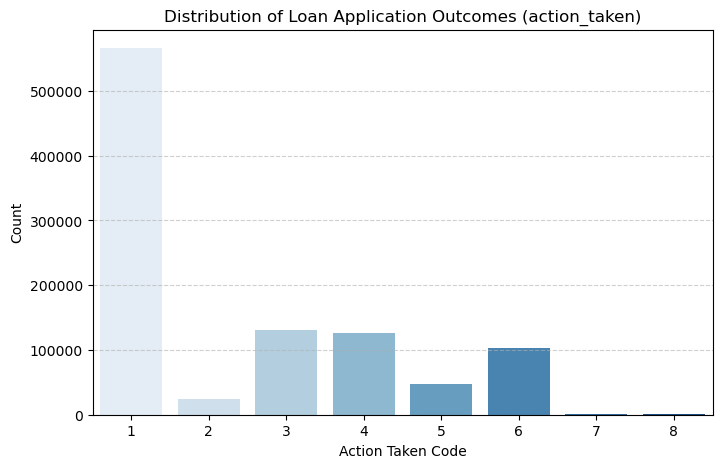

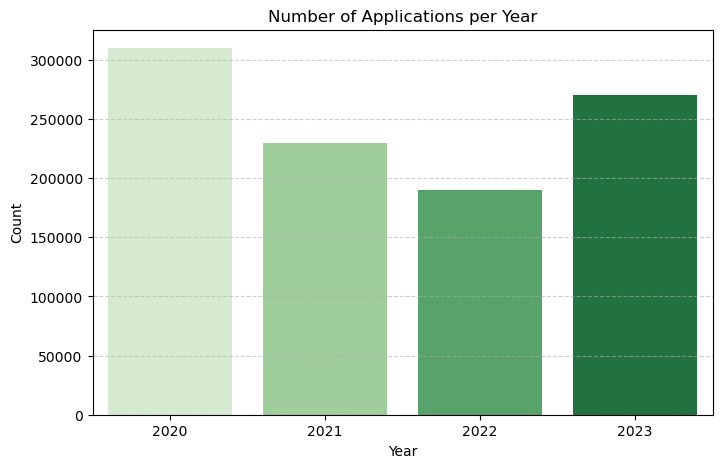

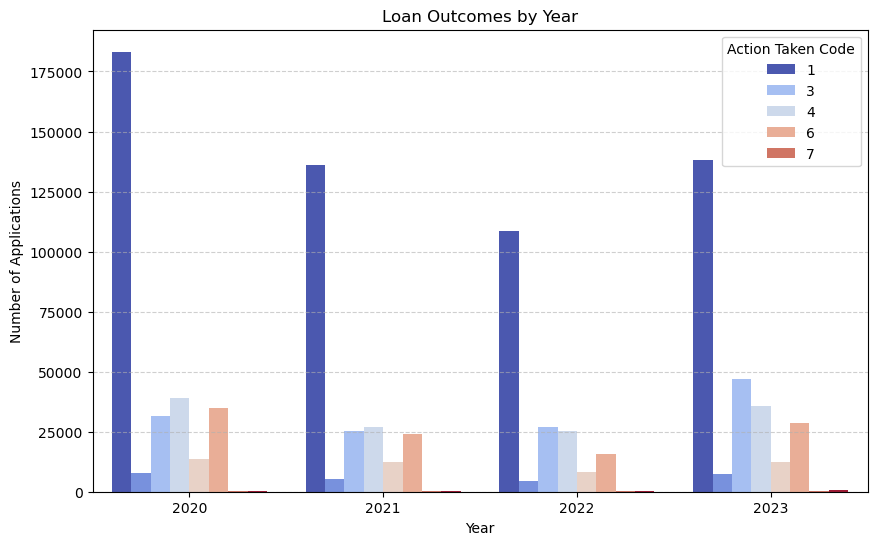

In [26]:
# --- Frequency table ---
print("📋 Action Taken (Counts & %):")
action_counts = selected_df['action_taken'].value_counts(dropna=False).sort_index()
action_perc = selected_df['action_taken'].value_counts(normalize=True, dropna=False).sort_index() * 100
action_table = pd.DataFrame({'Count': action_counts, 'Percent': action_perc.round(2)})
print(action_table)

print("\n📋 Activity Year (Counts):")
print(selected_df['activity_year'].value_counts().sort_index())

# --- Visualization 1: Action Taken Histogram ---
plt.figure(figsize=(8,5))
sns.countplot(data=selected_df, x='action_taken', palette='Blues')
plt.title('Distribution of Loan Application Outcomes (action_taken)')
plt.xlabel('Action Taken Code')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# --- Visualization 2: Applications per Year ---
plt.figure(figsize=(8,5))
sns.countplot(data=selected_df, x='activity_year', palette='Greens')
plt.title('Number of Applications per Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# --- Optional: Cross-tab Year vs Action Taken ---
plt.figure(figsize=(10,6))
sns.countplot(data=selected_df, x='activity_year', hue='action_taken', palette='coolwarm')
plt.title('Loan Outcomes by Year')
plt.xlabel('Year')
plt.ylabel('Number of Applications')
plt.legend(title='Action Taken Code')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

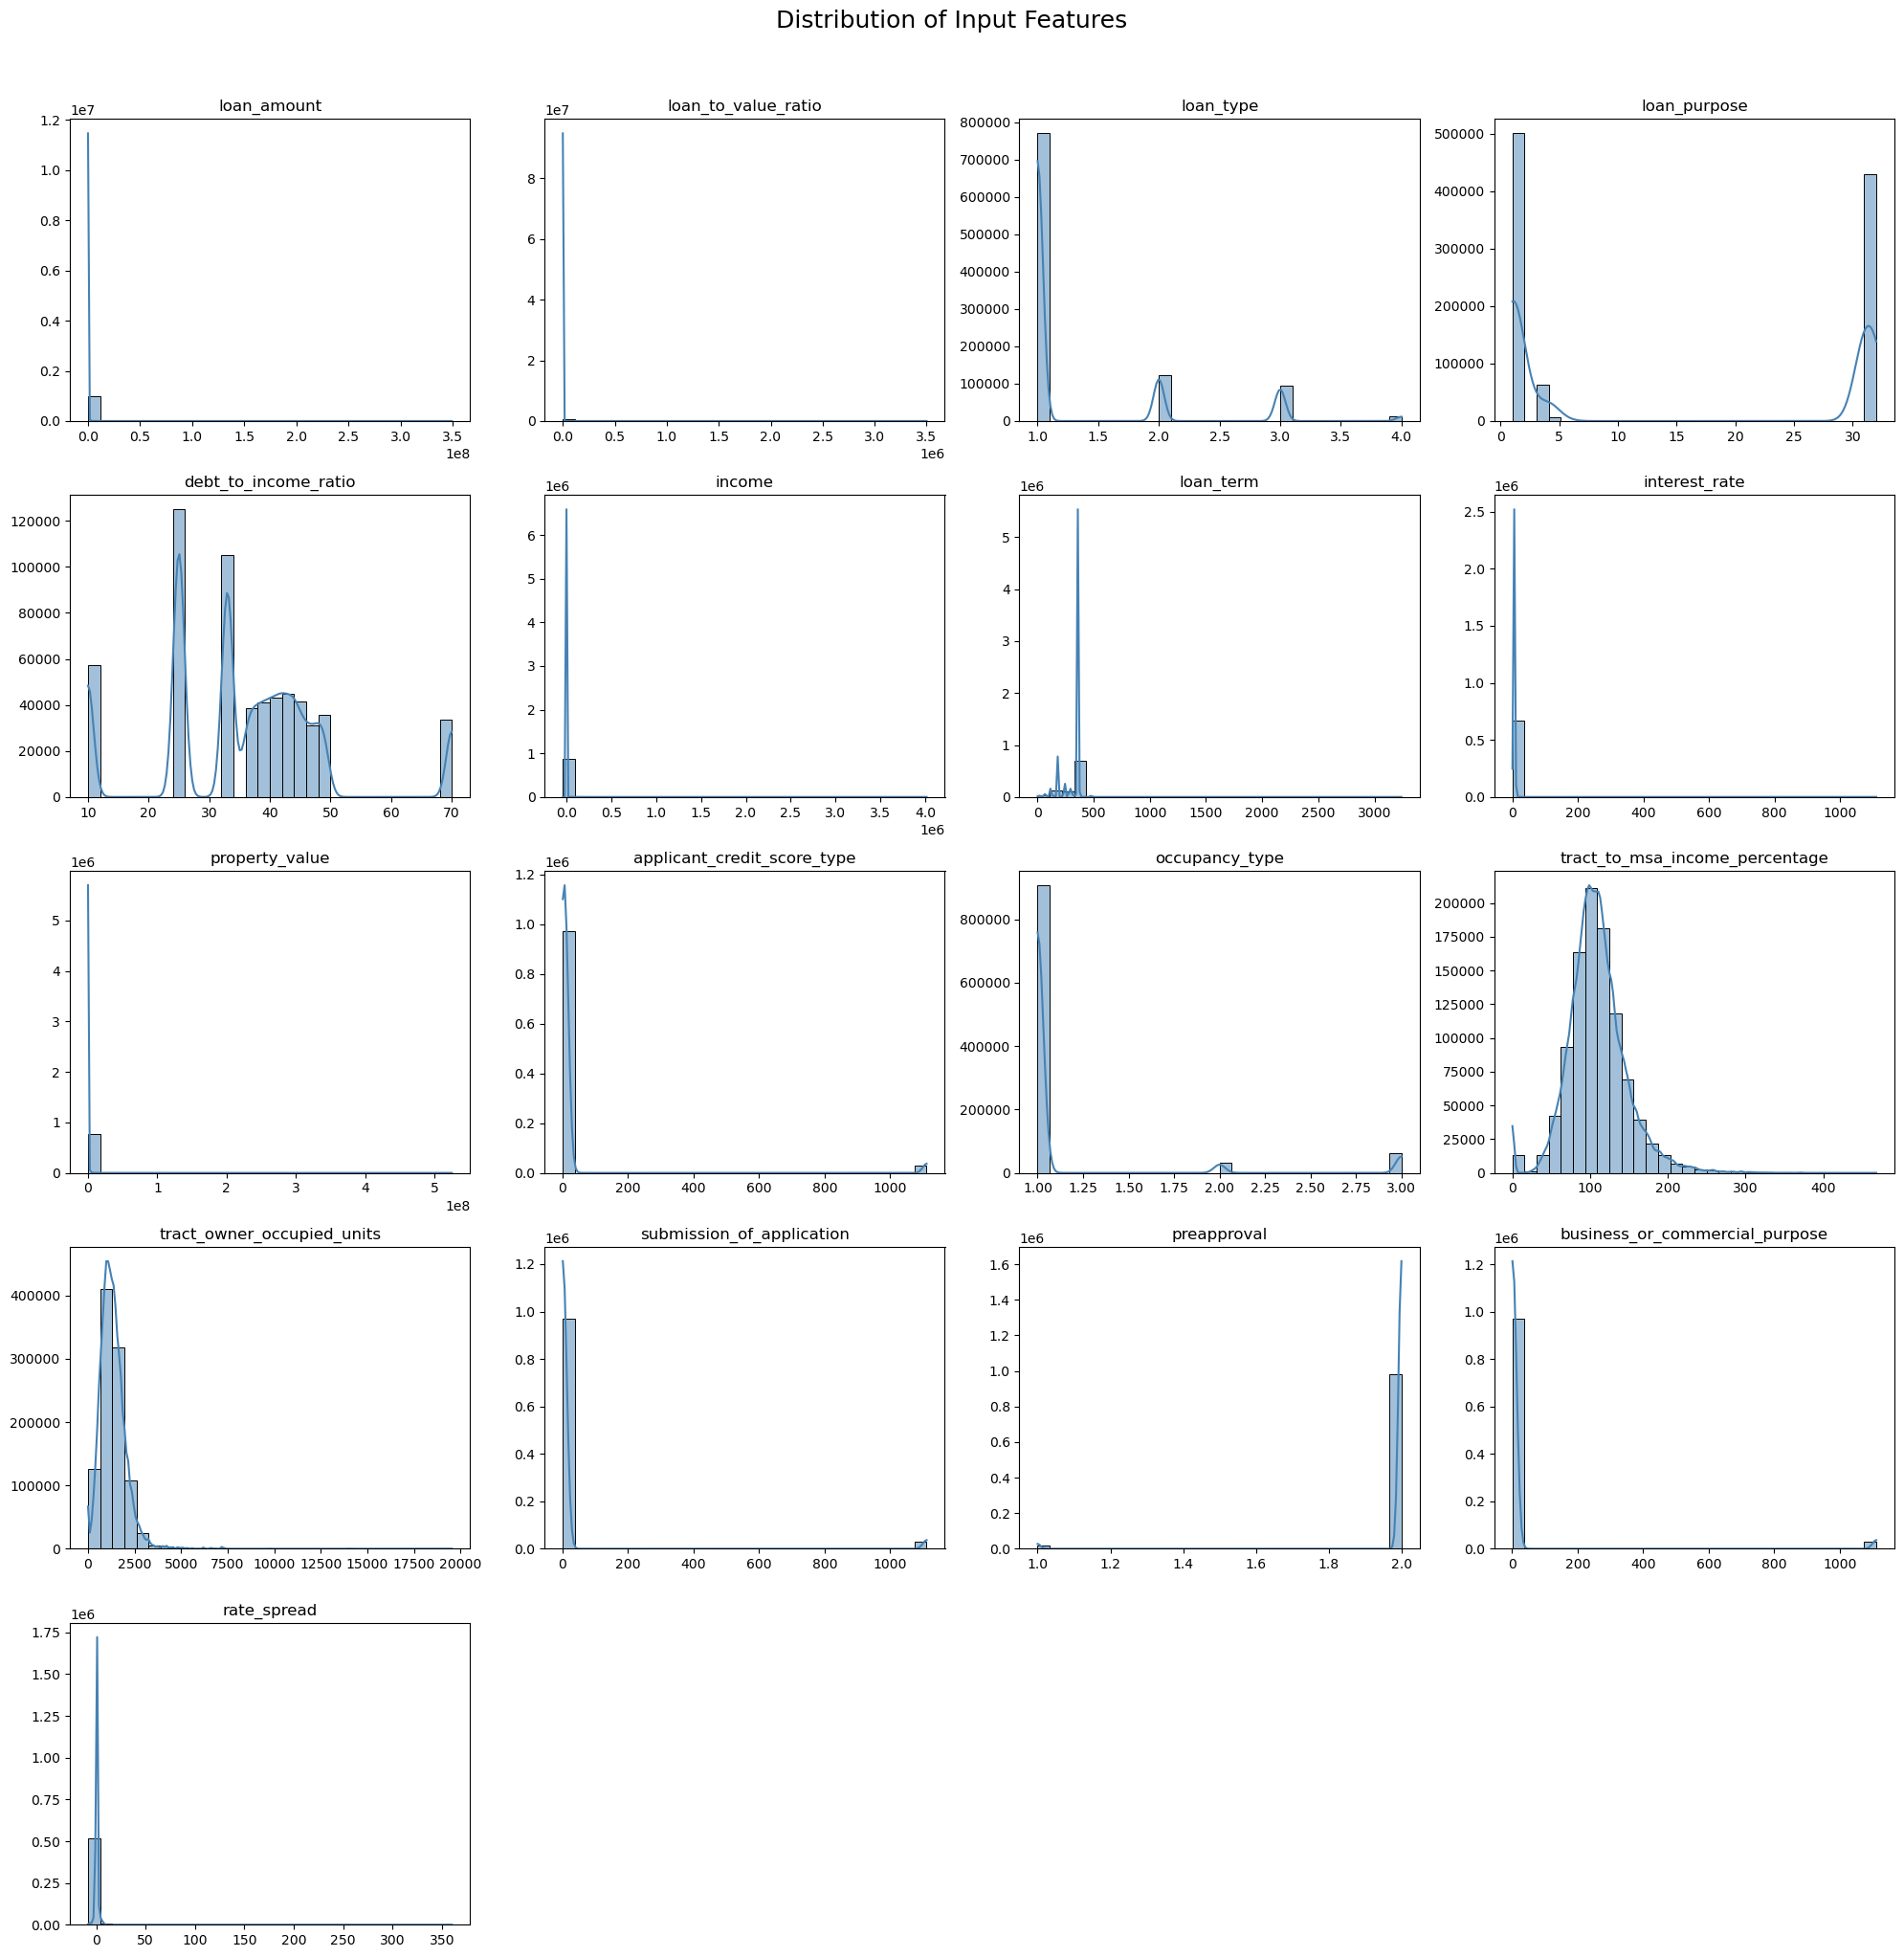

In [27]:
# List of input features
features = [
    'loan_amount', 'loan_to_value_ratio', 'loan_type', 'loan_purpose',
    'debt_to_income_ratio', 'income', 'loan_term', 'interest_rate',
    'property_value', 'applicant_credit_score_type', 'occupancy_type',
    'tract_to_msa_income_percentage', 'tract_owner_occupied_units',
    'submission_of_application', 'preapproval', 'business_or_commercial_purpose',
    'rate_spread'
]

# Determine grid size automatically (approx square layout)
n_features = len(features)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

plt.figure(figsize=(n_cols * 5, n_rows * 4))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, col in enumerate(features, 1):
    plt.subplot(n_rows, n_cols, i)
    if selected_df[col].dtype in ['float64', 'int64', 'int32']:
        # Numeric: use histogram
        sns.histplot(selected_df[col].dropna(), kde=True, bins=30, color='steelblue')
    else:
        # Categorical: use countplot
        sns.countplot(data=selected_df, x=col, palette='Set2')
        plt.xticks(rotation=45)
    plt.title(col)
    plt.xlabel('')
    plt.ylabel('')

plt.suptitle('Distribution of Input Features', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()


In [28]:
# Columns you want to inspect
cols_with_outliers = [
    'loan_amount',
    'loan_to_value_ratio',
    'income',
    'loan_term',
    'interest_rate',
    'property_value',
    'applicant_credit_score_type',
    'tract_owner_occupied_units',
    'rate_spread',
    'business_or_commercial_purpose'
]

# Loop through and print min, max, and top 5 frequent values
for col in cols_with_outliers:
    if col in selected_df.columns:
        print(f"\n🔹 {col}")
        print(f"   Min: {selected_df[col].min()}")
        print(f"   Max: {selected_df[col].max()}")
        print("   Top 5 most frequent values (%):")
        print(
            (selected_df[col].value_counts(normalize=True, dropna=False) * 100)
            .round(2)
            .head(5)
            .to_string()
        )
    else:
        print(f"\n⚠️ Column '{col}' not found in selected_df.")



🔹 loan_amount
   Min: 5000.0
   Max: 349005000.0
   Top 5 most frequent values (%):
loan_amount
105000.0    3.67
155000.0    3.32
205000.0    3.32
55000.0     2.90
165000.0    2.78

🔹 loan_to_value_ratio
   Min: 0.001
   Max: 3500000.0
   Top 5 most frequent values (%):
loan_to_value_ratio
NaN      35.70
80.0      6.47
95.0      3.19
96.5      2.69
100.0     2.34

🔹 income
   Min: -39671.0
   Max: 4015184.0
   Top 5 most frequent values (%):
income
NaN     13.67
0.0      0.99
60.0     0.99
70.0     0.83
75.0     0.83

🔹 loan_term
   Min: 1.0
   Max: 3240.0
   Top 5 most frequent values (%):
loan_term
360.0    68.73
180.0     9.52
240.0     4.93
NaN       4.04
300.0     3.45

🔹 interest_rate
   Min: 0.0
   Max: 1111.0
   Top 5 most frequent values (%):
interest_rate
NaN      32.98
2.875     4.17
2.750     4.16
3.250     3.61
3.125     2.66

🔹 property_value
   Min: 5000.0
   Max: 525005000.0
   Top 5 most frequent values (%):
property_value
NaN         23.15
255000.0     2.09
305000.0 

In [29]:
print("✅ Dataset shape before cleaning:", selected_df.shape)

# ---------------------------
# 1. loan_amount: keep 99.9% (0.05–99.95%)
# ---------------------------
lower, upper = selected_df['loan_amount'].quantile([0.0005, 0.9995])
selected_df = selected_df[
    ((selected_df['loan_amount'] >= lower) & (selected_df['loan_amount'] <= upper)) |
    (selected_df['loan_amount'].isna())
]
print("1 Dataset shape:", selected_df.shape)

# ---------------------------
# 2. income: remove <0, then keep 99.99% (0.05–99.99%)
# ---------------------------
selected_df = selected_df[selected_df['income'].isna() | (selected_df['income'] >= 0)]
lower, upper = selected_df['income'].quantile([0.0005, 0.9999])
selected_df = selected_df[
    ((selected_df['income'] >= lower) & (selected_df['income'] <= upper)) |
    (selected_df['income'].isna())
]
print("2 Dataset shape:", selected_df.shape)

# ---------------------------
# 3. loan_to_value_ratio: delete above 99th percentile, keep NaNs
# ---------------------------
p99 = selected_df['loan_to_value_ratio'].quantile(0.99)
selected_df = selected_df[
    (selected_df['loan_to_value_ratio'] <= p99) | (selected_df['loan_to_value_ratio'].isna())
]
print("3 Dataset shape:", selected_df.shape)

# ---------------------------
# 4. loan_term: replace outliers (and missing) with 360
# ---------------------------
selected_df['loan_term'] = selected_df['loan_term'].fillna(360)
selected_df.loc[
    (selected_df['loan_term'] < 60) | (selected_df['loan_term'] > 480),
    'loan_term'
] = 360
print("4 Dataset shape:", selected_df.shape)

# ---------------------------
# interest_rate: replace 1111 with NaN, then delete data above 99th percentile
# ---------------------------

# Step 1: Replace placeholder 1111 with NaN
selected_df['interest_rate'] = selected_df['interest_rate'].replace(1111, np.nan)

# Step 2: Compute 99th percentile threshold (ignore NaNs)
p99 = selected_df['interest_rate'].quantile(0.99)

# Step 3: Keep only values ≤ 99th percentile (and keep NaNs)
selected_df = selected_df[
    (selected_df['interest_rate'].isna()) | (selected_df['interest_rate'] <= p99)
]

print("5 Dataset shape:", selected_df.shape)

# ---------------------------
# 6. property_value: keep 99.9% (0.05–99.95%), keep NaNs
# ---------------------------
lower, upper = selected_df['property_value'].quantile([0.0005, 0.9995])
selected_df = selected_df[
    ((selected_df['property_value'] >= lower) & (selected_df['property_value'] <= upper)) |
    (selected_df['property_value'].isna())
]
print("6 Dataset shape:", selected_df.shape)

# ---------------------------
# 7. applicant_credit_score_type: replace 1111 with NaN
# ---------------------------
selected_df['applicant_credit_score_type'] = selected_df['applicant_credit_score_type'].replace(1111, np.nan)
print("7 Dataset shape:", selected_df.shape)

# ---------------------------
# 8. tract_owner_occupied_units: delete above 99th percentile, keep NaNs
# ---------------------------
p99 = selected_df['tract_owner_occupied_units'].quantile(0.99)
selected_df = selected_df[
    (selected_df['tract_owner_occupied_units'] <= p99) | (selected_df['tract_owner_occupied_units'].isna())
]
print("8 Dataset shape:", selected_df.shape)

# ---------------------------
# 9. rate_spread: keep 99.9% (0.05–99.95%), keep NaNs
# ---------------------------
lower, upper = selected_df['rate_spread'].quantile([0.0005, 0.9995])
selected_df = selected_df[
    ((selected_df['rate_spread'] >= lower) & (selected_df['rate_spread'] <= upper)) |
    (selected_df['rate_spread'].isna())
]
print("9 Dataset shape:", selected_df.shape)

# ---------------------------
# 10. business_or_commercial_purpose: replace 1111 with NaN
# ---------------------------
selected_df['business_or_commercial_purpose'] = selected_df['business_or_commercial_purpose'].replace(1111, np.nan)

# ---------------------------
# 11. submission_of_application: replace 1111 with NaN
# ---------------------------
selected_df['submission_of_application'] = selected_df['submission_of_application'].replace(1111, np.nan)

# ---------------------------
# Final check
# ---------------------------
print("✅ Cleaned dataset shape:", selected_df.shape)


✅ Dataset shape before cleaning: (1000000, 29)
1 Dataset shape: (999500, 29)
2 Dataset shape: (998827, 29)
3 Dataset shape: (992407, 29)
4 Dataset shape: (992407, 29)
5 Dataset shape: (985746, 29)
6 Dataset shape: (985105, 29)
7 Dataset shape: (985105, 29)
8 Dataset shape: (975258, 29)
9 Dataset shape: (974751, 29)
✅ Cleaned dataset shape: (974751, 29)


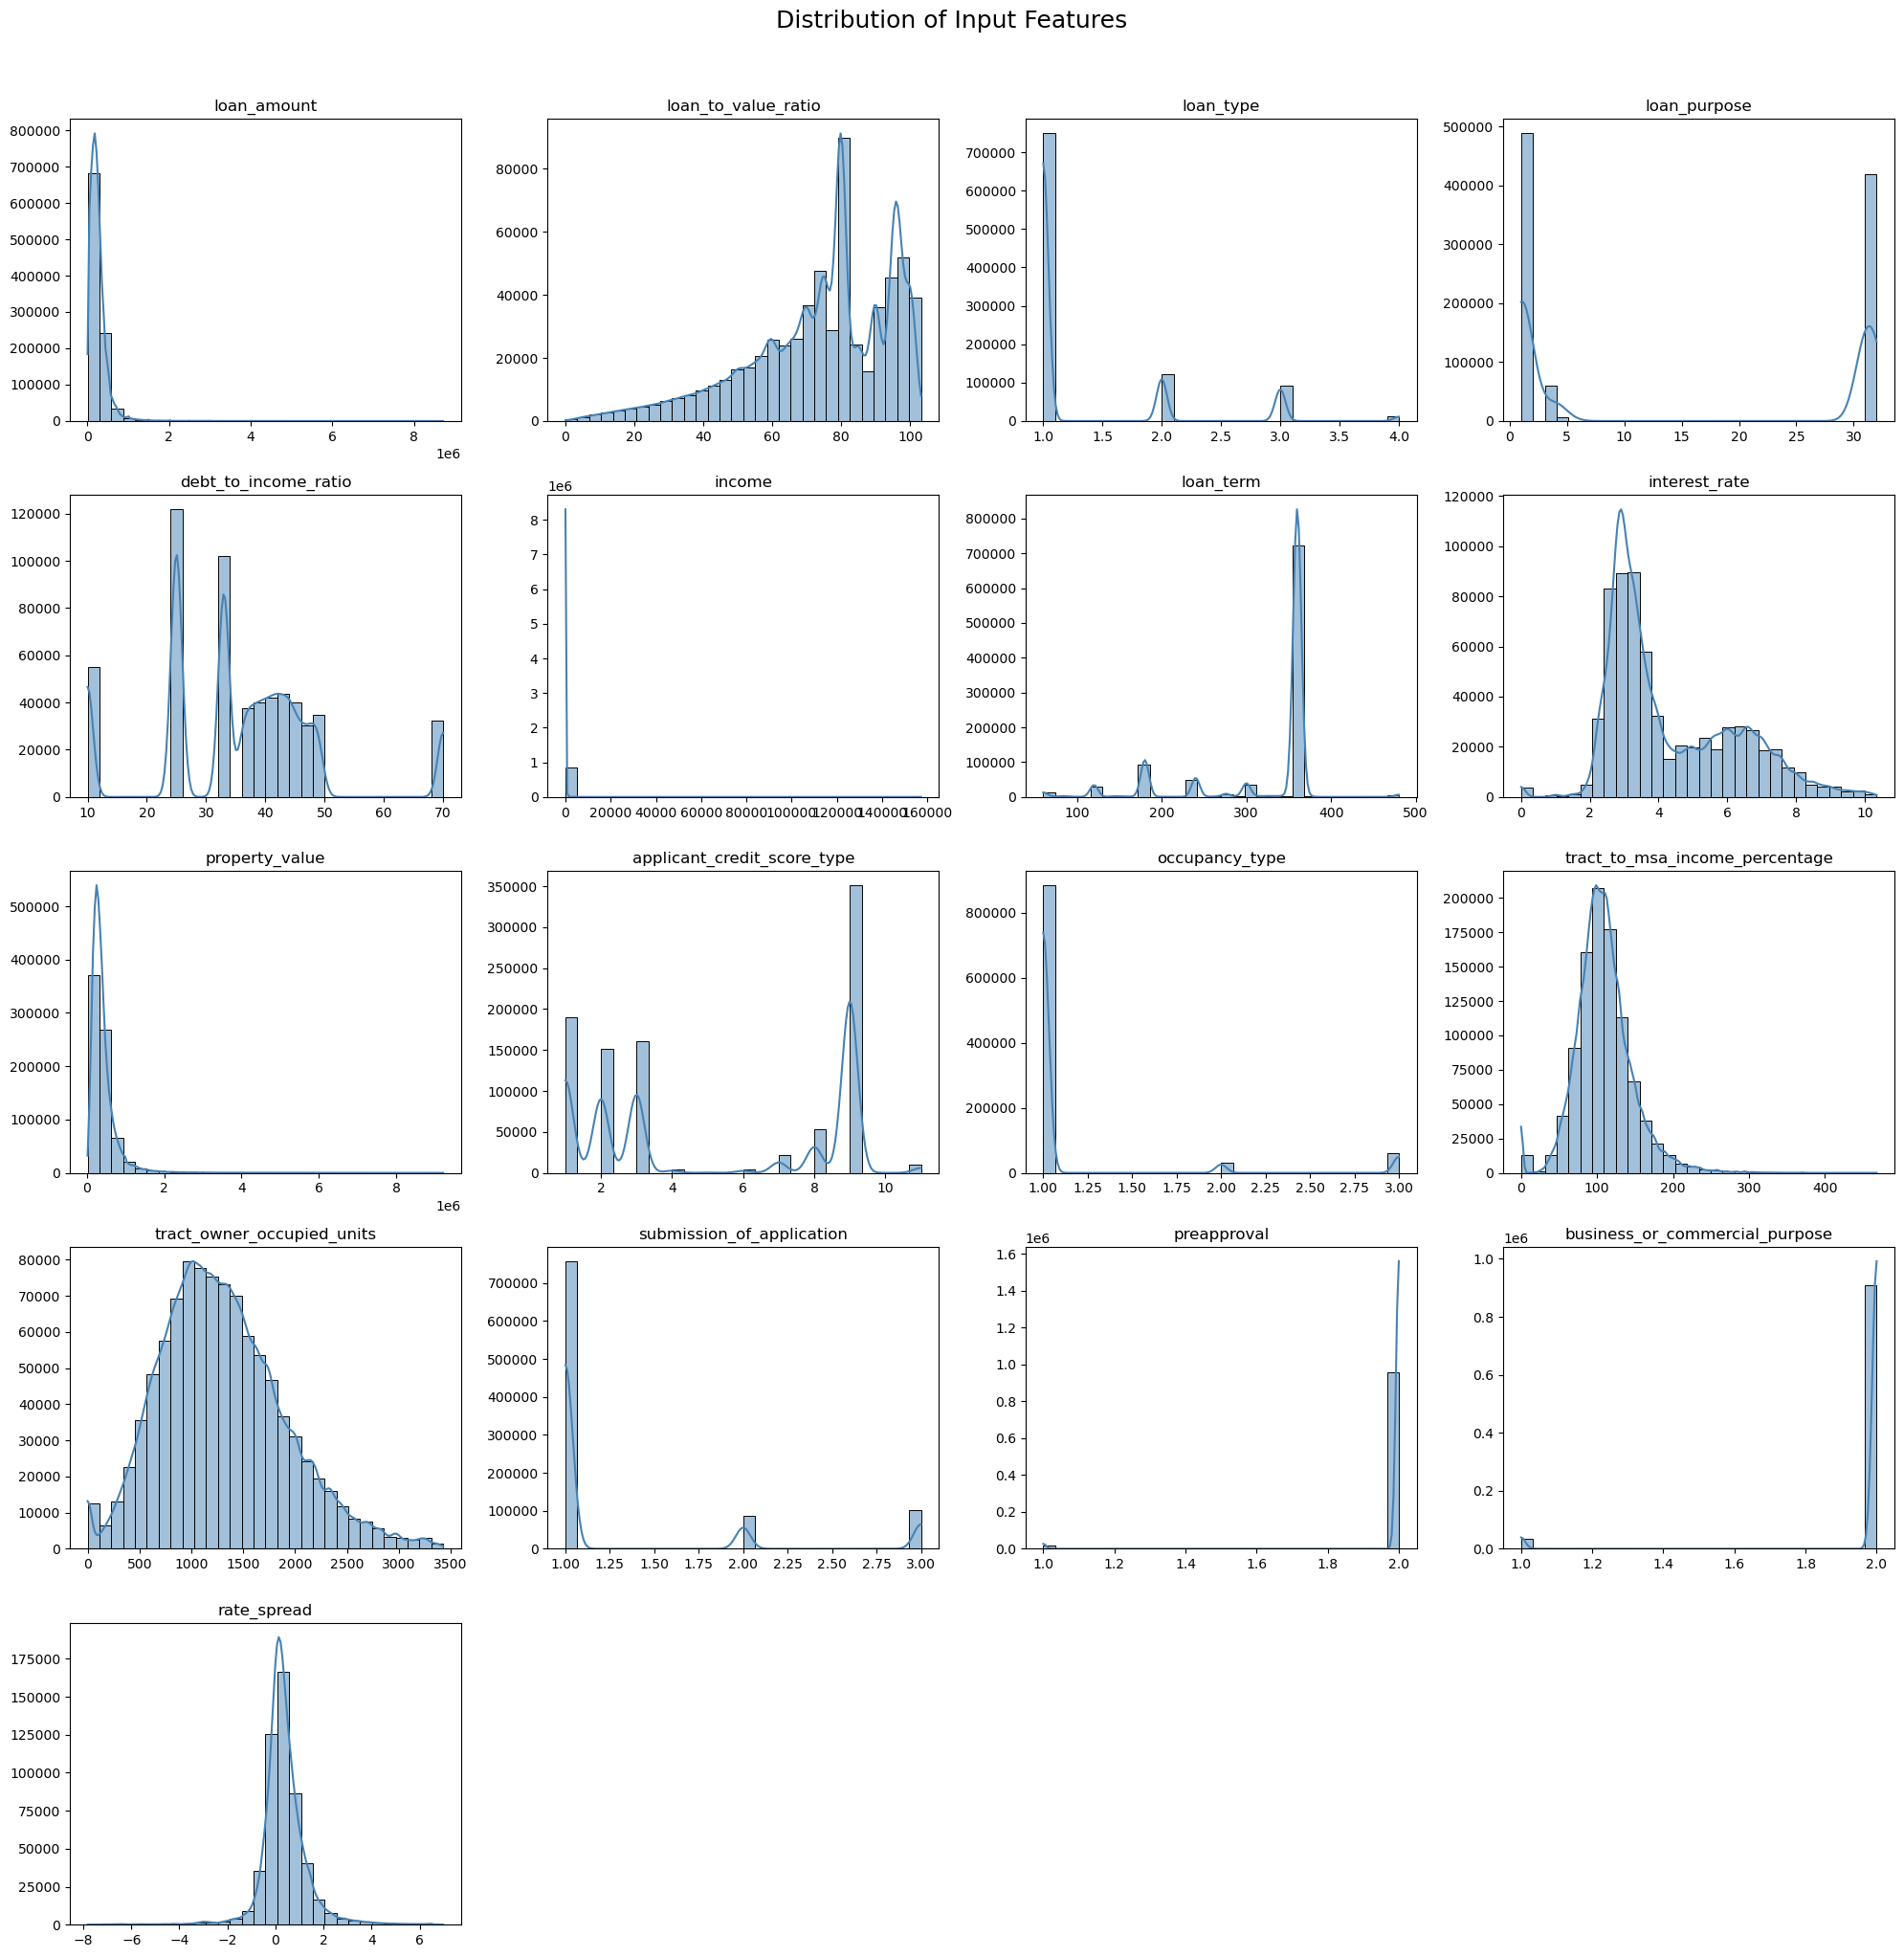

In [30]:
# List of input features
features = [
    'loan_amount', 'loan_to_value_ratio', 'loan_type', 'loan_purpose',
    'debt_to_income_ratio', 'income', 'loan_term', 'interest_rate',
    'property_value', 'applicant_credit_score_type', 'occupancy_type',
    'tract_to_msa_income_percentage', 'tract_owner_occupied_units',
    'submission_of_application', 'preapproval', 'business_or_commercial_purpose',
    'rate_spread'
]

# Determine grid size automatically (approx square layout)
n_features = len(features)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

plt.figure(figsize=(n_cols * 5, n_rows * 4))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, col in enumerate(features, 1):
    plt.subplot(n_rows, n_cols, i)
    if selected_df[col].dtype in ['float64', 'int64', 'int32']:
        # Numeric: use histogram
        sns.histplot(selected_df[col].dropna(), kde=True, bins=30, color='steelblue')
    else:
        # Categorical: use countplot
        sns.countplot(data=selected_df, x=col, palette='Set2')
        plt.xticks(rotation=45)
    plt.title(col)
    plt.xlabel('')
    plt.ylabel('')

plt.suptitle('Distribution of Input Features', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()


In [31]:
# Columns you want to inspect
cols_with_outliers = [
    'loan_amount',
    'loan_to_value_ratio',
    'income',
    'loan_term',
    'interest_rate',
    'property_value',
    'applicant_credit_score_type',
    'tract_owner_occupied_units',
    'rate_spread',
    'business_or_commercial_purpose'
]

# Loop through and print min, max, and top 5 frequent values
for col in cols_with_outliers:
    if col in selected_df.columns:
        print(f"\n🔹 {col}")
        print(f"   Min: {selected_df[col].min()}")
        print(f"   Max: {selected_df[col].max()}")
        print("   Top 5 most frequent values (%):")
        print(
            (selected_df[col].value_counts(normalize=True, dropna=False) * 100)
            .round(2)
            .head(5)
            .to_string()
        )
    else:
        print(f"\n⚠️ Column '{col}' not found in selected_df.")



🔹 loan_amount
   Min: 5000.0
   Max: 8715000.0
   Top 5 most frequent values (%):
loan_amount
105000.0    3.68
155000.0    3.34
205000.0    3.33
55000.0     2.82
165000.0    2.79

🔹 loan_to_value_ratio
   Min: 0.001
   Max: 103.108
   Top 5 most frequent values (%):
loan_to_value_ratio
NaN      36.06
80.0      6.54
95.0      3.23
96.5      2.73
100.0     2.37

🔹 income
   Min: 0.0
   Max: 157186.0
   Top 5 most frequent values (%):
income
NaN     13.62
0.0      0.99
60.0     0.99
70.0     0.83
75.0     0.83

🔹 loan_term
   Min: 60.0
   Max: 480.0
   Top 5 most frequent values (%):
loan_term
360.0    73.86
180.0     9.48
240.0     4.86
300.0     3.41
120.0     3.02

🔹 interest_rate
   Min: 0.0
   Max: 10.35
   Top 5 most frequent values (%):
interest_rate
NaN      33.04
2.875     4.19
2.750     4.18
3.250     3.63
3.125     2.68

🔹 property_value
   Min: 25000.0
   Max: 9205000.0
   Top 5 most frequent values (%):
property_value
NaN         23.49
255000.0     2.08
305000.0     1.98
225

In [32]:
# Check the null values
null_counts = selected_df.isnull().sum()
null_counts.sort_values(ascending=False).head(30)

rate_spread                          461604
debt_to_income_ratio                 394804
loan_to_value_ratio                  351489
interest_rate                        322058
property_value                       228974
income                               132760
applicant_credit_score_type           29150
submission_of_application             29079
business_or_commercial_purpose        29008
census_tract                          10275
county_code                            7469
activity_year                             0
derived_sex                               0
derived_ethnicity                         0
derived_race                              0
applicant_age                             0
tract_minority_population_percent         0
lei                                       0
loan_amount                               0
tract_to_msa_income_percentage            0
preapproval                               0
tract_owner_occupied_units                0
state_code                      

In [33]:
import numpy as np
import pandas as pd

def impute_missing_values(df):
    """Impute missing values in the selected_df according to mortgage domain logic."""

    # --- Helper: mode filler ---
    def fill_mode(group):
        mode_val = group.mode().iloc[0] if not group.mode().empty else np.nan
        return group.fillna(mode_val)

    # --- rate_spread ---
    df['rate_spread'] = df['rate_spread'].fillna(0)

    # --- loan_to_value_ratio ---
    df['loan_to_value_ratio'] = df['loan_to_value_ratio'].fillna(-1)

    # --- debt_to_income_ratio ---
    df['debt_to_income_ratio'] = (
        df.groupby(['loan_type', 'loan_purpose'])['debt_to_income_ratio']
        .transform(lambda x: x.fillna(x.median()))
    )
    mask_missing = df['debt_to_income_ratio'].isna()
    df.loc[mask_missing, 'debt_to_income_ratio'] = (
        df[mask_missing]
        .groupby('loan_purpose')['debt_to_income_ratio']
        .transform(lambda x: x.fillna(x.median()))
    )

    # --- interest_rate ---
    df['interest_rate'] = df['interest_rate'].replace(1111, np.nan)
    df['interest_rate'] = (
        df.groupby(['county_code', 'loan_type'])['interest_rate']
        .transform(lambda x: x.fillna(x.median()))
    )
    mask_missing = df['interest_rate'].isna()
    df.loc[mask_missing, 'interest_rate'] = (
        df[mask_missing]
        .groupby(['state_code', 'loan_type'])['interest_rate']
        .transform(lambda x: x.fillna(x.median()))
    )
    df['interest_rate'] = df['interest_rate'].fillna(df['interest_rate'].median())

    # --- property_value ---
    df['property_value'] = (
        df.groupby(['county_code', 'loan_purpose', 'loan_type'])['property_value']
        .transform(lambda x: x.fillna(x.median()))
    )
    mask_missing = df['property_value'].isna()
    df.loc[mask_missing, 'property_value'] = (
        df[mask_missing]
        .groupby(['state_code', 'loan_purpose', 'loan_type'])['property_value']
        .transform(lambda x: x.fillna(x.median()))
    )
    df['property_value'] = df['property_value'].fillna(df['property_value'].median())

    # --- income ---
    df['income'] = (
        df.groupby(['loan_type', 'loan_purpose', 'state_code'])['income']
        .transform(lambda x: x.fillna(x.median()))
    )
    df['income'] = df['income'].fillna(df['income'].median())

    # --- business_or_commercial_purpose ---
    df['business_or_commercial_purpose'] = df['business_or_commercial_purpose'].replace(1111, np.nan)
    df['business_or_commercial_purpose'] = (
        df.groupby(['loan_purpose', 'loan_type', 'county_code'])['business_or_commercial_purpose']
        .transform(fill_mode)
    )
    mask_missing = df['business_or_commercial_purpose'].isna()
    df.loc[mask_missing, 'business_or_commercial_purpose'] = (
        df[mask_missing]
        .groupby(['loan_purpose', 'loan_type', 'state_code'])['business_or_commercial_purpose']
        .transform(fill_mode)
    )
    df['business_or_commercial_purpose'] = df['business_or_commercial_purpose'].fillna(
        df['business_or_commercial_purpose'].mode().iloc[0]
    )

    # --- applicant_credit_score_type ---
    df['applicant_credit_score_type'] = df['applicant_credit_score_type'].replace(1111, np.nan)
    df['applicant_credit_score_type'] = (
        df.groupby(['county_code', 'loan_type'])['applicant_credit_score_type']
        .transform(fill_mode)
    )
    mask_missing = df['applicant_credit_score_type'].isna()
    df.loc[mask_missing, 'applicant_credit_score_type'] = (
        df[mask_missing]
        .groupby(['state_code', 'loan_type'])['applicant_credit_score_type']
        .transform(fill_mode)
    )
    df['applicant_credit_score_type'] = df['applicant_credit_score_type'].fillna(
        df['applicant_credit_score_type'].mode().iloc[0]
    )

    # --- submission_of_application ---
    df['submission_of_application'] = (
        df.groupby('loan_purpose')['submission_of_application']
        .transform(fill_mode)
    )
    df['submission_of_application'] = df['submission_of_application'].fillna(
        df['submission_of_application'].mode().iloc[0]
    )

    print("✅ All missing values imputed successfully.")
    return df


In [34]:
selected_df = impute_missing_values(selected_df)

✅ All missing values imputed successfully.


In [35]:
# Check the null values
null_counts = selected_df.isnull().sum()
null_counts.sort_values(ascending=False).head(30)

census_tract                         10275
county_code                           7469
debt_to_income_ratio                  6168
loan_amount                              0
submission_of_application                0
lei                                      0
applicant_age                            0
derived_sex                              0
derived_ethnicity                        0
derived_race                             0
tract_minority_population_percent        0
rate_spread                              0
activity_year                            0
business_or_commercial_purpose           0
preapproval                              0
tract_to_msa_income_percentage           0
tract_owner_occupied_units               0
loan_to_value_ratio                      0
state_code                               0
occupancy_type                           0
derived_loan_product_type                0
applicant_credit_score_type              0
property_value                           0
interest_ra

In [36]:
# Step 3: Global fallback for any remaining missing DTI
global_median_dti = selected_df['debt_to_income_ratio'].median()
selected_df['debt_to_income_ratio'] = selected_df['debt_to_income_ratio'].fillna(global_median_dti)

In [37]:
# Check the null values
null_counts = selected_df.isnull().sum()
null_counts.sort_values(ascending=False).head(30)

census_tract                         10275
county_code                           7469
loan_amount                              0
tract_owner_occupied_units               0
lei                                      0
applicant_age                            0
derived_sex                              0
derived_ethnicity                        0
derived_race                             0
tract_minority_population_percent        0
rate_spread                              0
activity_year                            0
business_or_commercial_purpose           0
preapproval                              0
submission_of_application                0
tract_to_msa_income_percentage           0
loan_to_value_ratio                      0
state_code                               0
occupancy_type                           0
derived_loan_product_type                0
applicant_credit_score_type              0
property_value                           0
interest_rate                            0
loan_term  

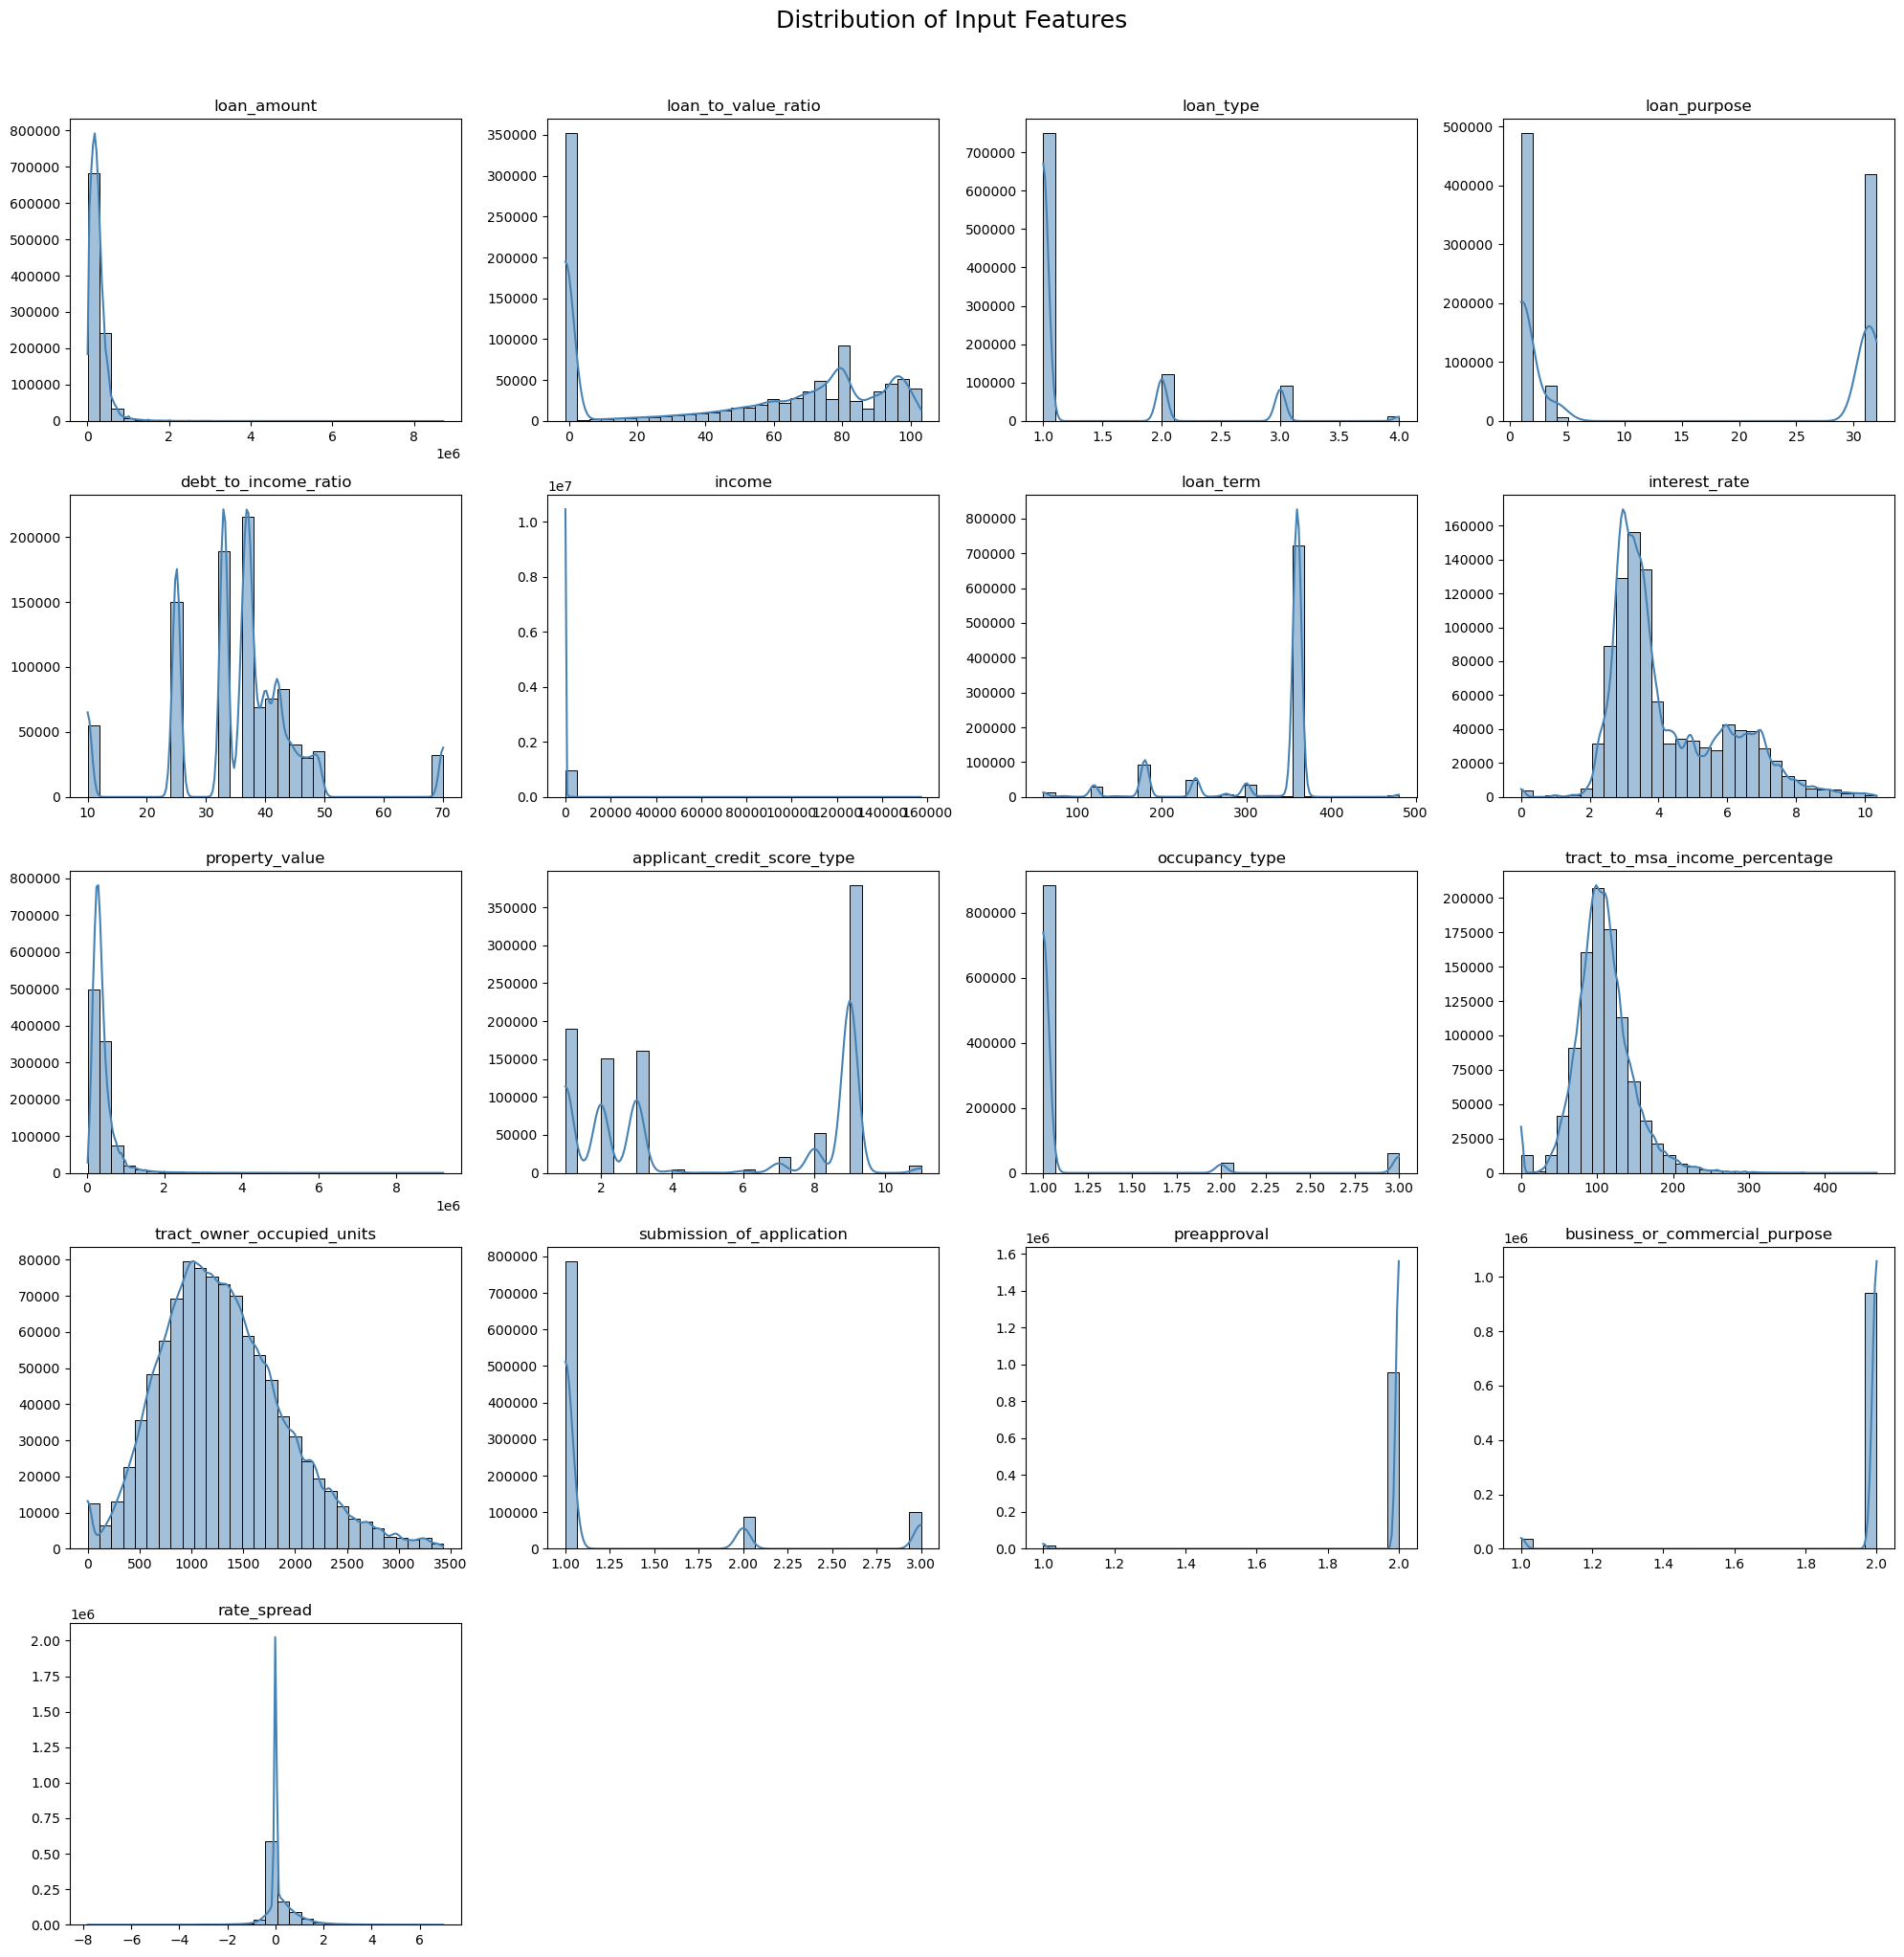

In [38]:
# List of input features
features = [
    'loan_amount', 'loan_to_value_ratio', 'loan_type', 'loan_purpose',
    'debt_to_income_ratio', 'income', 'loan_term', 'interest_rate',
    'property_value', 'applicant_credit_score_type', 'occupancy_type',
    'tract_to_msa_income_percentage', 'tract_owner_occupied_units',
    'submission_of_application', 'preapproval', 'business_or_commercial_purpose',
    'rate_spread'
]

# Determine grid size automatically (approx square layout)
n_features = len(features)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

plt.figure(figsize=(n_cols * 5, n_rows * 4))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, col in enumerate(features, 1):
    plt.subplot(n_rows, n_cols, i)
    if selected_df[col].dtype in ['float64', 'int64', 'int32']:
        # Numeric: use histogram
        sns.histplot(selected_df[col].dropna(), kde=True, bins=30, color='steelblue')
    else:
        # Categorical: use countplot
        sns.countplot(data=selected_df, x=col, palette='Set2')
        plt.xticks(rotation=45)
    plt.title(col)
    plt.xlabel('')
    plt.ylabel('')

plt.suptitle('Distribution of Input Features', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()


In [39]:
# truist_census_df

In [40]:
print("✅ Cleaned dataset shape:", selected_df.shape)

✅ Cleaned dataset shape: (974751, 29)


In [41]:
# Save cleaned dataset to Google Drive
output_path = "clean_hmda_random_sample_2020_2023.csv"

selected_df.to_csv(output_path, index=False)

print(f"✅ Cleaned dataset successfully saved to:\n{output_path}")


✅ Cleaned dataset successfully saved to:
clean_hmda_random_sample_2020_2023.csv
